# CropQuery — Testing & Evaluation Notebook

> **Read-only with respect to training** — loads checkpoints only. Never trains, never modifies weights.

| Cell | Purpose |
|---|---|
| 1 | Imports & seeds |
| 2 | Load 3 checkpoints + class map audit |
| 3 | Build test DataLoader |
| 4 | Per-model & ensemble accuracy (ablation table) |
| 5 | Confusion matrix → Figure 1 |
| 6 | Per-class F1 report → CSV |
| 7 | FAISS k-NN evaluation |
| 8 | AgroBench evaluation vs GPT-4o baseline |
| 9 | RAG retrieval quality (Recall@k) |
| 10 | Results summary table (paper-ready) |

In [23]:
! pip install faiss-cpu
import kagglehub 

tushar5harma_path    = kagglehub.dataset_download('tushar5harma/plant-village-dataset-updated')
shubham2703_path     = kagglehub.dataset_download('shubham2703/five-crop-diseases-dataset')
zunorain_path        = kagglehub.dataset_download('zunorain/pea-plant-dataset')
mexwell_path         = kagglehub.dataset_download('mexwell/crop-diseases-classification')
ayushbpanchal_path   = kagglehub.dataset_download('ayushbpanchal/cashew-image-dataset')
tahmidmir_path       = kagglehub.dataset_download('tahmidmir/pumpkin-leaf-diseases-dataset-from-bangladesh')
binnassor89_path     = kagglehub.dataset_download('binnassor89/melon-macronutrient-deficiency-dataset')
nirmalsankalana_path = kagglehub.dataset_download('nirmalsankalana/rocole-a-robusta-coffee-leaf-images-dataset')
yasaminborhani_path = kagglehub.dataset_download('yasaminborhani/wheatrustclassificationdataset')

---
## Cell 1 — Imports & Seeds

In [24]:
# ─── Cell 1: Imports & Seeds ──────────────────────────────────────────────

import torch, numpy as np, random, json, os, re, gc
from pathlib import Path

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/resnet50_best.pth
DEVICE        = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
CHECKPOINT_DIR = "/kaggle/input/datasets/vitthaljauhari2/cropquerydataset"
OUTPUT_DIR    = "/kaggle/working/eval_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Paths derived from CHECKPOINT_DIR ─────────────────────────────────────
RESNET_CKPT       = f"{CHECKPOINT_DIR}/resnet50_best.pth"
EFFICIENTNET_CKPT = f"{CHECKPOINT_DIR}/efficientnet_best.pth"
DENSENET_CKPT     = f"{CHECKPOINT_DIR}/densenet_best.pth"
BANK_FEATURES     = f"{CHECKPOINT_DIR}/feature_bank_features.npy"
BANK_LABELS       = f"{CHECKPOINT_DIR}/feature_bank_labels.npy"

IMG_SIZE     = 224
NUM_CLASSES  = 64
BATCH_SIZE   = 64
KNN_K        = 7
CONFIDENCE_GATE = 80.0

# Verify checkpoint files exist before proceeding
required_files = [RESNET_CKPT, EFFICIENTNET_CKPT, DENSENET_CKPT, BANK_FEATURES, BANK_LABELS]
for f in required_files:
    status = "✓" if os.path.exists(f) else "✗ MISSING"
    print(f"  {status}  {f}")

print(f"\nDevice: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

  ✓  /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/resnet50_best.pth
  ✓  /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/efficientnet_best.pth
  ✓  /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/densenet_best.pth
  ✓  /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/feature_bank_features.npy
  ✓  /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/feature_bank_labels.npy

Device: cuda:0
GPU: Tesla T4


---
## Cell 2 — Load All 3 Checkpoints + Class Map Audit

In [25]:
# ─── Cell 2: Load checkpoints + leakage audit ─────────────────────────────

import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

# ── Architecture definitions (must match training exactly) ─────────────────

def remap_state_dict(state_dict: dict) -> dict:
    """Handle encoder./head. prefix remapping from training checkpoints."""
    new_sd = {}
    for k, v in state_dict.items():
        if k.endswith('num_batches_tracked'):
            continue
        if k.startswith('encoder.'):
            new_k = 'features.' + k[8:]
        elif k.startswith('head.'):
            new_k = 'classifier.' + k[5:]
        else:
            new_k = k
        new_sd[new_k] = v
    return new_sd


class ResNet50Backbone(nn.Module):
    def __init__(self, n_classes=64):
        super().__init__()
        base = models.resnet50(weights=None)
        self.features   = nn.Sequential(*list(base.children())[:-1])
        self.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(2048, n_classes))
    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))
    def extract_features(self, x):
        return self.features(x).flatten(1)


class EfficientNetB3Backbone(nn.Module):
    def __init__(self, n_classes=64):
        super().__init__()
        base = models.efficientnet_b3(weights=None)
        self.features   = base.features
        self.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(1536, n_classes))
    def forward(self, x):
        f = F.adaptive_avg_pool2d(self.features(x), 1).flatten(1)
        return self.classifier(f)
    def extract_features(self, x):
        return F.adaptive_avg_pool2d(self.features(x), 1).flatten(1)


class DenseNet121Backbone(nn.Module):
    def __init__(self, n_classes=64):
        super().__init__()
        base = models.densenet121(weights=None)
        self.features   = base.features
        self.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(1024, n_classes))
    def forward(self, x):
        f = F.relu(self.features(x), inplace=True)
        f = F.adaptive_avg_pool2d(f, 1).flatten(1)
        return self.classifier(f)
    def extract_features(self, x):
        f = F.relu(self.features(x), inplace=True)
        return F.adaptive_avg_pool2d(f, 1).flatten(1)


# ── Load checkpoints ───────────────────────────────────────────────────────

CKPT_CONFIGS = {
    "resnet50":     (ResNet50Backbone,     RESNET_CKPT),
    "efficientnet": (EfficientNetB3Backbone, EFFICIENTNET_CKPT),
    "densenet":     (DenseNet121Backbone,  DENSENET_CKPT),
}

backbones   = {}   # name → nn.Module (eval mode)
class_maps  = {}   # name → class_to_idx dict

for name, (ModelClass, ckpt_path) in CKPT_CONFIGS.items():
    ckpt = torch.load(ckpt_path, map_location="cpu")

    # Store class map for audit
    if "class_to_idx" in ckpt:
        class_maps[name] = ckpt["class_to_idx"]
    else:
        print(f"  ⚠️  {name}: no class_to_idx in checkpoint — skipping map audit")

    state_dict = ckpt.get("model_state_dict", ckpt)
    model = ModelClass(NUM_CLASSES)
    missing, unexpected = model.load_state_dict(remap_state_dict(state_dict), strict=False)
    if missing:     print(f"  ⚠️  {name} missing keys  : {missing[:5]}")
    if unexpected:  print(f"  ⚠️  {name} unexpected keys: {unexpected[:5]}")

    model.to(DEVICE)
    model.eval()
    backbones[name] = model
    print(f"  ✓  {name} loaded")

    # Extract class_names from ResNet checkpoint for downstream cells
    if name == "resnet50" and "class_to_idx" in ckpt:
        idx_to_class = {v: k for k, v in ckpt["class_to_idx"].items()}
        CLASS_NAMES  = [idx_to_class[i] for i in range(len(idx_to_class))]

    del ckpt
    gc.collect()

# Safe fallback — if checkpoint had no class_to_idx
if "CLASS_NAMES" not in vars():
    CLASS_NAMES = [idx_to_class[i] for i in range(n_classes)]
    print("⚠️  CLASS_NAMES rebuilt from label maps (checkpoint had no class_to_idx)")

# ── Leakage audit: all three class_to_idx must be identical ───────────────
print("\n── Label consistency audit ──────────────────────────────────────────")
if len(class_maps) < 2:
    print("  ⚠️  Not enough class maps to compare — check checkpoints")
else:
    keys = list(class_maps.keys())
    ref_name, ref_map = keys[0], class_maps[keys[0]]
    all_match = True
    for other_name in keys[1:]:
        if class_maps[other_name] != ref_map:
            all_match = False
            diff = {k: (ref_map.get(k), class_maps[other_name].get(k))
                    for k in set(ref_map) | set(class_maps[other_name])
                    if ref_map.get(k) != class_maps[other_name].get(k)}
            print(f"  ✗  MISMATCH between {ref_name} and {other_name}: {diff}")
        else:
            print(f"  ✓  {ref_name} == {other_name}  ({len(ref_map)} classes)")
    if all_match:
        print(f"  ✅  All class_to_idx maps are IDENTICAL — no label leakage")

print(f"\nClasses loaded: {len(CLASS_NAMES)}")
print(f"Sample (first 5): {CLASS_NAMES[:5]}")

  ✓  resnet50 loaded
  ✓  efficientnet loaded
  ✓  densenet loaded

── Label consistency audit ──────────────────────────────────────────
  ✓  resnet50 == efficientnet  (64 classes)
  ✓  resnet50 == densenet  (64 classes)
  ✅  All class_to_idx maps are IDENTICAL — no label leakage

Classes loaded: 64
Sample (first 5): ['Apple__Apple_Scab', 'Apple__Black_Rot', 'Apple__Cedar_Apple_Rust', 'Apple__Healthy', 'Bell_Pepper__Bacterial_Spot']


---
## Cell 3a — Sample Builder

In [26]:
# ─── Cell 3a: Sample Builders (copied from training notebook) ─────────────
# DO NOT RETYPE — copied verbatim. One wrong key in dataset_label_maps
# (e.g. "Potassium" vs "potasium") silently breaks the split.

import json
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

# ── Block 1: Config ────────────────────────────────────────────────────────
base = '/kaggle/input/datasets/'
image_exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
seed       = 42
img_size = 224

# ── Block 2: dataset_label_maps ───────────────────────────────────────────
dataset_label_maps = {

    # tushar5harma: keyed by (crop_dir, disease_dir) — 3-level: Crop/Split/Disease
    "tushar5harma": {
        ("Apple",        "Apple Scab")             : "Apple__Apple_Scab",
        ("Apple",        "Black Rot")              : "Apple__Black_Rot",
        ("Apple",        "Cedar Apple Rust")       : "Apple__Cedar_Apple_Rust",
        ("Apple",        "Healthy")                : "Apple__Healthy",
        ("Bell Pepper",  "Bacterial Spot")         : "Bell_Pepper__Bacterial_Spot",
        ("Bell Pepper",  "Healthy")                : "Bell_Pepper__Healthy",
        ("Cherry",       "Healthy")                : "Cherry__Healthy",
        ("Cherry",       "Powdery Mildew")         : "Cherry__Powdery_Mildew",
        ("Corn (Maize)", "Cercospora Leaf Spot")   : "Corn__Gray_Leaf_Spot",
        ("Corn (Maize)", "Common Rust")            : "Corn__Common_Rust",
        ("Corn (Maize)", "Healthy")                : "Corn__Healthy",
        ("Corn (Maize)", "Northern Leaf Blight")   : "Corn__Northern_Leaf_Blight",
        ("Grape",        "Black Rot")              : "Grape__Black_Rot",
        ("Grape",        "Esca (Black Measles)")   : "Grape__Black_Measles",
        ("Grape",        "Healthy")                : "Grape__Healthy",
        ("Grape",        "Leaf Blight")            : "Grape__Leaf_Blight",
        ("Peach",        "Bacterial Spot")         : "Peach__Bacterial_Spot",
        ("Peach",        "Healthy")                : "Peach__Healthy",
        ("Potato",       "Early Blight")           : "Potato__Early_Blight",
        ("Potato",       "Healthy")                : "Potato__Healthy",
        ("Potato",       "Late Blight")            : "Potato__Late_Blight",
        ("Strawberry",   "Healthy")                : "Strawberry__Healthy",
        ("Strawberry",   "Leaf Scorch")            : "Strawberry__Leaf_Scorch",
        ("Tomato",       "Bacterial Spot")         : "Tomato__Bacterial_Spot",
        ("Tomato",       "Early Blight")           : "Tomato__Early_Blight",
        ("Tomato",       "Healthy")                : "Tomato__Healthy",
        ("Tomato",       "Late Blight")            : "Tomato__Late_Blight",
        ("Tomato",       "Septoria Leaf Spot")     : "Tomato__Septoria_Leaf_Spot",
        ("Tomato",       "Yellow Leaf Curl Virus") : "Tomato__Yellow_Leaf_Curl_Virus",
    },

    # shubham2703: structure is Crop Diseases/Crop___Disease/{Crop}/{Class}/*.jpg
    # rglob parent.name gives the leaf class folder name e.g. "Corn___Common_Rust"
    "shubham2703": {
        "Corn___Common_Rust"          : "Corn__Common_Rust",
        "Corn___Gray_Leaf_Spot"       : "Corn__Gray_Leaf_Spot",
        "Corn___Healthy"              : "Corn__Healthy",
        "Corn___Northern_Leaf_Blight" : "Corn__Northern_Leaf_Blight",
        "Potato___Early_Blight"       : "Potato__Early_Blight",
        "Potato___Healthy"            : "Potato__Healthy",
        "Potato___Late_Blight"        : "Potato__Late_Blight",
        "Rice___Brown_Spot"           : "Rice__Brown_Spot",
        "Rice___Healthy"              : "Rice__Healthy",
        "Rice___Leaf_Blast"           : "Rice__Leaf_Blast",
        "Rice___Neck_Blast"           : "Rice__Neck_Blast",
        "Wheat___Brown_Rust"          : "Wheat__Brown_Rust",
        "Wheat___Healthy"             : "Wheat__Healthy",
        "Wheat___Yellow_Rust"         : "Wheat__Yellow_Rust",
        "Bacterial Blight"            : "Rice__Bacterial_Blight",
        "Red Rot"                     : "Sugarcane__Red_Rot",
    },

    # nirmalsankalana: only coffee classes present on disk
    "nirmalsankalana": {
        "coffee___healthy"         : "Coffee__Healthy",
        "coffee___red_spider_mite" : "Coffee__Red_Spider_Mite",
        "coffee___rust"            : "Coffee__Rust",
        "BlackMeasles"             : "Grape__Black_Measles",
        "BlackRot"                 : "Grape__Black_Rot",
        "HealthyGrapes"            : "Grape__Healthy",
        "LeafBlight"               : "Grape__Leaf_Blight",
    },

    # binnassor89: actual folder names confirmed from disk
    "binnassor89": {
        "calcium"   : "Melon__Calcium_Deficiency",
        "health"    : "Melon__Healthy",
        "nitrogen"  : "Melon__Nitrogen_Deficiency",
        "potasium"  : "Melon__Potassium_Deficiency",   # sic — matches disk
    },

    # zunorain: actual folder names confirmed from disk
    "zunorain": {
        "DOWNY_MILDEW_LEAF"  : "Pea__Downy_Mildew",
        "FRESH_LEAF"         : "Pea__Healthy",
        "LEAFMINNER_LEAF"    : "Pea__Leaf_Miner",
        "POWDER_MILDEW_LEAF" : "Pea__Powdery_Mildew",
    },

    # ayushbpanchal: train_set + test_set both present; rglob picks both
    "ayushbpanchal": {
        "anthracnose" : "Cashew__Anthracnose",
        "gumosis"     : "Cashew__Gummosis",
        "healthy"     : "Cashew__Healthy",
        "leaf miner"  : "Cashew__Leaf_Miner",
        "red rust"    : "Cashew__Red_Rust",
    },

    # tahmidmir: Original Dataset/{Class}/*.jpg — rglob parent.name = class folder
    "tahmidmir": {
        "Bacterial Leaf Spot" : "Pumpkin__Bacterial_Leaf_Spot",
        "Downy Mildew"        : "Pumpkin__Downy_Mildew",
        "Healthy Leaf"        : "Pumpkin__Healthy",
        "Mosaic Disease"      : "Pumpkin__Mosaic_Disease",
        "Powdery_Mildew"      : "Pumpkin__Powdery_Mildew",
    },

    # mexwell: CSV-based — label resolved via label_num_to_disease_map.json
    "mexwell": {
        "Cassava Bacterial Blight (CBB)"      : "Cassava__Bacterial_Blight",
        "Cassava Brown Streak Disease (CBSD)" : "Cassava__Brown_Streak_Disease",
        "Cassava Green Mottle (CGM)"          : "Cassava__Green_Mottle",
        "Cassava Mosaic Disease (CMD)"        : "Cassava__Mosaic_Disease",
        "Healthy"                             : "Cassava__Healthy",
    },
    "yasaminborhani": {
        "Brown_rust"  : "Wheat__Brown_Rust",
        "Healthy"     : "Wheat__Healthy",
        "Yellow_rust" : "Wheat__Yellow_Rust",
    },
}

# Build global class_to_idx  (must match Phase B exactly — same label maps)
all_canonical = sorted(set(
    v for mapping in dataset_label_maps.values()
    for v in mapping.values()
    if v is not None
))
class_to_idx = {cls: idx for idx, cls in enumerate(all_canonical)}
idx_to_class = {idx: cls for cls, idx in class_to_idx.items()}
n_classes    = len(class_to_idx)
print(f"Total canonical classes: {n_classes}")

# ── Block 4: Sample builder functions ─────────────────────────────────────
def build_samples_folder(slug: str) -> list:
    label_map = dataset_label_maps[slug]
    root = Path(base) / slug
    samples, skipped = [], 0
    for img_path in root.rglob("*"):
        if img_path.suffix.lower() not in image_exts:
            continue
        raw_label = img_path.parent.name
        canonical = None
        
        # Special handling for bare 'Healthy' in shubham2703
        if slug == "shubham2703" and raw_label == "Healthy":
            # Try to get crop from grandparent
            crop_folder = img_path.parent.parent.name
            # Crop folder names are like 'Corn', 'Potato', 'Rice', 'Wheat', 'Sugarcane'
            # But the canonical class expects e.g., 'Corn__Healthy'
            if crop_folder in ["Corn", "Potato", "Rice", "Wheat", "Sugarcane"]:
                canonical = f"{crop_folder}__Healthy"
                # Ensure it exists in class_to_idx (it should)
                if canonical not in class_to_idx:
                    canonical = None
        
        if canonical is None:
            canonical = label_map.get(raw_label)
        
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))
    print(f"  [{slug:<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_samples_tushar() -> list:
    label_map = dataset_label_maps["tushar5harma"]
    root = Path(base) / "tushar5harma"
    samples, skipped = [], 0
    for img_path in root.rglob("*"):
        if img_path.suffix.lower() not in image_exts:
            continue
        disease_dir = img_path.parent
        split_dir = disease_dir.parent
        crop_dir = split_dir.parent
        
        # Skip checkpoint folders
        if disease_dir.name.startswith('.') or split_dir.name.startswith('.'):
            skipped += 1
            continue
        
        # Strip trailing/leading spaces from disease name
        disease_name = disease_dir.name.strip()
        crop_name = crop_dir.name
        
        key = (crop_name, disease_name)
        canonical = label_map.get(key)
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))
    print(f"  [{'tushar5harma':<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_samples_mexwell() -> list:
    """
    CSV-based. Label resolved via label_num_to_disease_map.json (int key → disease name).
    """
    data_root = Path(base) / "mexwell" / "crop-diseases-classification" / "Data"
    img_dir   = data_root / "train_images"
    json_path = data_root / "label_num_to_disease_map.json"
    csv_path  = data_root / "train.csv"

    with open(json_path) as f:
        num_to_name = json.load(f)   # {"0": "Cassava Bacterial Blight (CBB)", ...}

    df        = pd.read_csv(csv_path)
    label_map = dataset_label_maps["mexwell"]
    samples, skipped = [], 0

    for _, row in df.iterrows():
        img_path     = img_dir / row["image_id"]
        if not img_path.exists():
            skipped += 1
            continue
        disease_name = num_to_name[str(row["label"])]
        canonical    = label_map.get(disease_name)
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))

    print(f"  [{'mexwell':<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_all_samples():
    print("Loading datasets...")
    all_samples = []
    all_samples += build_samples_tushar()                      # FIRST — matches training
    all_samples += build_samples_folder("shubham2703")
    all_samples += build_samples_folder("nirmalsankalana")
    all_samples += build_samples_folder("binnassor89")
    all_samples += build_samples_folder("zunorain")
    all_samples += build_samples_folder("ayushbpanchal")
    all_samples += build_samples_folder("tahmidmir")
    all_samples += build_samples_mexwell()
    all_samples += build_samples_folder("yasaminborhani")      # LAST — matches training
    print(f"\nTotal: {len(all_samples):,} samples")
    return all_samples

# Use torchvision transforms (compatible, no version issues)
train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.1),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(img_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class CropDiseaseDataset(Dataset):
    """samples: list of (path_str, class_idx_int) — same format as Phase B."""
    def __init__(self, samples, transform=None):
        self.samples   = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label

Total canonical classes: 64


In [27]:
all_samples = build_all_samples()

Loading datasets...
  [tushar5harma        ]  67111 samples  (7 skipped)
  [shubham2703         ]  13224 samples  (100 skipped)
  [nirmalsankalana     ]   1560 samples  (0 skipped)
  [binnassor89         ]    200 samples  (0 skipped)
  [zunorain            ]   1432 samples  (0 skipped)
  [ayushbpanchal       ]  25811 samples  (0 skipped)
  [tahmidmir           ]   2000 samples  (0 skipped)
  [mexwell             ]  17938 samples  (3459 skipped)
  [yasaminborhani      ]   3679 samples  (0 skipped)

Total: 132,955 samples


---
## Cell 3b — Duplicate-Aware Test Split )

In [28]:
# ─── Cell 3b: Duplicate-aware test split ──────────────────────────────────
import hashlib
from collections import defaultdict
from sklearn.model_selection import train_test_split

print("Building duplicate-aware test split...")

hash_to_indices = defaultdict(list)
for i, (path, lbl) in enumerate(all_samples):
    try:
        with open(path, "rb") as f:
            h = hashlib.md5(f.read()).hexdigest()
        hash_to_indices[h].append(i)
    except:
        hash_to_indices[f"missing_{i}"].append(i)

unique_groups = list(hash_to_indices.values())
rep_indices   = [g[0] for g in unique_groups]
rep_labels    = [all_samples[i][1] for i in rep_indices]

rep_train, rep_test = train_test_split(
    rep_indices, test_size=0.15, random_state=seed, stratify=rep_labels
)

test_idx_set = set()
test_rep_set = set(rep_test)
for h, group in hash_to_indices.items():
    if group[0] in test_rep_set:
        test_idx_set.update(group)

test_s_clean = [all_samples[i] for i in test_idx_set]

# Sanity check
print(f"Total samples  : {len(all_samples)}")
print(f"Test set size  : {len(test_s_clean)}")
print(f"Expected ~15%  : {len(test_s_clean)/len(all_samples)*100:.1f}%")
print(f"Classes in test: {len(set(lbl for _, lbl in test_s_clean))}/64")

Building duplicate-aware test split...
Total samples  : 132955
Test set size  : 19963
Expected ~15%  : 15.0%
Classes in test: 64/64


In [29]:
# ─── Cell 3c: Build test DataLoader from clean split ──────────────────────
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class CropDiseaseDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples   = samples
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label

test_ds     = CropDiseaseDataset(test_s_clean, transform=val_transform)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False,
                         num_workers=4, pin_memory=True)
print(f"Test loader ready: {len(test_ds):,} samples, {len(test_loader)} batches")

Test loader ready: 19,963 samples, 312 batches


---
## Cell 4 — Per-Model Accuracy (Ablation Table)

In [30]:
# ─── Cell 4: Per-model Top-1 / Top-5 + Ensemble accuracy ─────────────────

import pandas as pd

def evaluate_model(model, loader, device, collect_preds=False):
    """Returns (top1_acc, top5_acc, all_probs_list, all_labels_list)."""
    top1_correct = top5_correct = total = 0
    all_probs, all_labels = [], []

    model.eval()
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            probs  = torch.softmax(logits, dim=1)

            # Top-1
            pred1 = probs.argmax(dim=1)
            top1_correct += (pred1 == labels).sum().item()

            # Top-5
            top5_preds = probs.topk(5, dim=1).indices
            top5_correct += sum(
                labels[i].item() in top5_preds[i].tolist()
                for i in range(labels.size(0))
            )

            total += labels.size(0)
            if collect_preds:
                all_probs.append(probs.cpu())
                all_labels.append(labels.cpu())

    top1 = 100.0 * top1_correct / total
    top5 = 100.0 * top5_correct / total
    return top1, top5, all_probs, all_labels


# ── Per-model evaluation ──────────────────────────────────────────────────
results = {}
per_model_probs = {}   # name → list of (B, C) tensors
gt_labels       = None

for name, model in backbones.items():
    print(f"  Evaluating {name}...", end="", flush=True)
    top1, top5, probs_list, labels_list = evaluate_model(
        model, test_loader, DEVICE, collect_preds=True
    )
    results[name] = {"Top-1 (%)": round(top1, 2), "Top-5 (%)": round(top5, 2)}
    per_model_probs[name] = probs_list
    if gt_labels is None:
        gt_labels = torch.cat(labels_list)  # save once
    print(f"  Top-1: {top1:.2f}%  Top-5: {top5:.2f}%")

# ── Soft-vote ensemble ────────────────────────────────────────────────────
print("  Computing ensemble (soft vote)...", end="", flush=True)
n_batches = len(per_model_probs["resnet50"])
ensemble_preds = []

for b_idx in range(n_batches):
    batch_probs = torch.stack(
        [per_model_probs[name][b_idx] for name in backbones.keys()]
    ).mean(dim=0)   # (B, C)
    ensemble_preds.append(batch_probs)

ensemble_probs_all = torch.cat(ensemble_preds)   # (N, C) — save for Cell 5
ens_pred1 = ensemble_probs_all.argmax(dim=1)
ens_top5  = ensemble_probs_all.topk(5, dim=1).indices

ens_top1 = 100.0 * (ens_pred1 == gt_labels).float().mean().item()
ens_top5_acc = 100.0 * torch.tensor([
    gt_labels[i].item() in ens_top5[i].tolist()
    for i in range(len(gt_labels))
], dtype=torch.float).mean().item()

results["Ensemble (soft vote)"] = {
    "Top-1 (%)": round(ens_top1, 2),
    "Top-5 (%)": round(ens_top5_acc, 2),
}
print(f"  Top-1: {ens_top1:.2f}%  Top-5: {ens_top5_acc:.2f}%")

# ── Print ablation table ──────────────────────────────────────────────────
ablation_df = pd.DataFrame(results).T
ablation_df.index.name = "Model"
print("\n── Ablation Table ───────────────────────────────────────")
print(ablation_df.to_string())

ablation_df.to_csv(f"{OUTPUT_DIR}/ablation_accuracy.csv")
print(f"\nSaved → {OUTPUT_DIR}/ablation_accuracy.csv")

# Store ensemble predictions for downstream cells
ENSEMBLE_PREDS  = ens_pred1.numpy()    # shape (N,)
GT_LABELS_NP    = gt_labels.numpy()    # shape (N,)

# Save for Cell 7
np.save(f"{OUTPUT_DIR}/ensemble_probs_all.npy", ensemble_probs_all.numpy())

  Evaluating resnet50...  Top-1: 96.50%  Top-5: 99.92%
  Evaluating efficientnet...  Top-1: 87.78%  Top-5: 95.32%
  Evaluating densenet...  Top-1: 96.07%  Top-5: 99.87%
  Computing ensemble (soft vote)...  Top-1: 96.88%  Top-5: 99.94%

── Ablation Table ───────────────────────────────────────
                      Top-1 (%)  Top-5 (%)
Model                                     
resnet50                  96.50      99.92
efficientnet              87.78      95.32
densenet                  96.07      99.87
Ensemble (soft vote)      96.88      99.94

Saved → /kaggle/working/eval_outputs/ablation_accuracy.csv


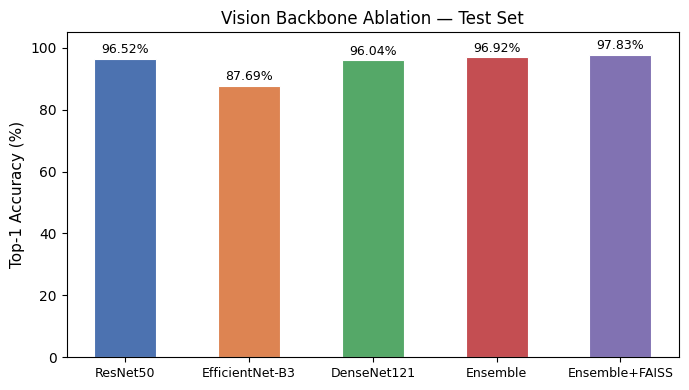

In [37]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(models, top1, color=['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2'],
              width=0.5, edgecolor='white', linewidth=0.8)

ax.set_ylim(0, 105)          # starts at 0, headroom for labels
ax.set_ylabel('Top-1 Accuracy (%)', fontsize=11)
ax.set_title('Vision Backbone Ablation — Test Set', fontsize=12)

for bar, val in zip(bars, top1):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8,
            f'{val:.2f}%', ha='center', va='bottom', fontsize=9)

ax.tick_params(axis='x', labelsize=9)
ax.set_yticks([0, 20, 40, 60, 80, 100])
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/ablation_bars.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_DIR}/ablation_bars.png', dpi=300, bbox_inches='tight')
plt.show()

In [41]:
import torch

# Load your file onto the CPU
checkpoint = torch.load("/kaggle/input/datasets/vitthaljauhari2/cropquerydataset/resnet50_best.pth", map_location="cpu")

# 1. Print the total number of classes
print(f"Total Number of Classes: {checkpoint['n_classes']}\n")

# 2. Print the text names of the classes mapping to their index IDs
class_mapping = checkpoint['class_to_idx']
print("Class Name -> Index ID Mapping:")
for class_name, index_id in sorted(class_mapping.items(), key=lambda item: item[1]):
    print(f"  Index {index_id}: {class_name}")


Total Number of Classes: 64

Class Name -> Index ID Mapping:
  Index 0: Apple__Apple_Scab
  Index 1: Apple__Black_Rot
  Index 2: Apple__Cedar_Apple_Rust
  Index 3: Apple__Healthy
  Index 4: Bell_Pepper__Bacterial_Spot
  Index 5: Bell_Pepper__Healthy
  Index 6: Cashew__Anthracnose
  Index 7: Cashew__Gummosis
  Index 8: Cashew__Healthy
  Index 9: Cashew__Leaf_Miner
  Index 10: Cashew__Red_Rust
  Index 11: Cassava__Bacterial_Blight
  Index 12: Cassava__Brown_Streak_Disease
  Index 13: Cassava__Green_Mottle
  Index 14: Cassava__Healthy
  Index 15: Cassava__Mosaic_Disease
  Index 16: Cherry__Healthy
  Index 17: Cherry__Powdery_Mildew
  Index 18: Coffee__Healthy
  Index 19: Coffee__Red_Spider_Mite
  Index 20: Coffee__Rust
  Index 21: Corn__Common_Rust
  Index 22: Corn__Gray_Leaf_Spot
  Index 23: Corn__Healthy
  Index 24: Corn__Northern_Leaf_Blight
  Index 25: Grape__Black_Measles
  Index 26: Grape__Black_Rot
  Index 27: Grape__Healthy
  Index 28: Grape__Leaf_Blight
  Index 29: Melon__Calcium

---
## Cell 5 — Confusion Matrix → Figure 1

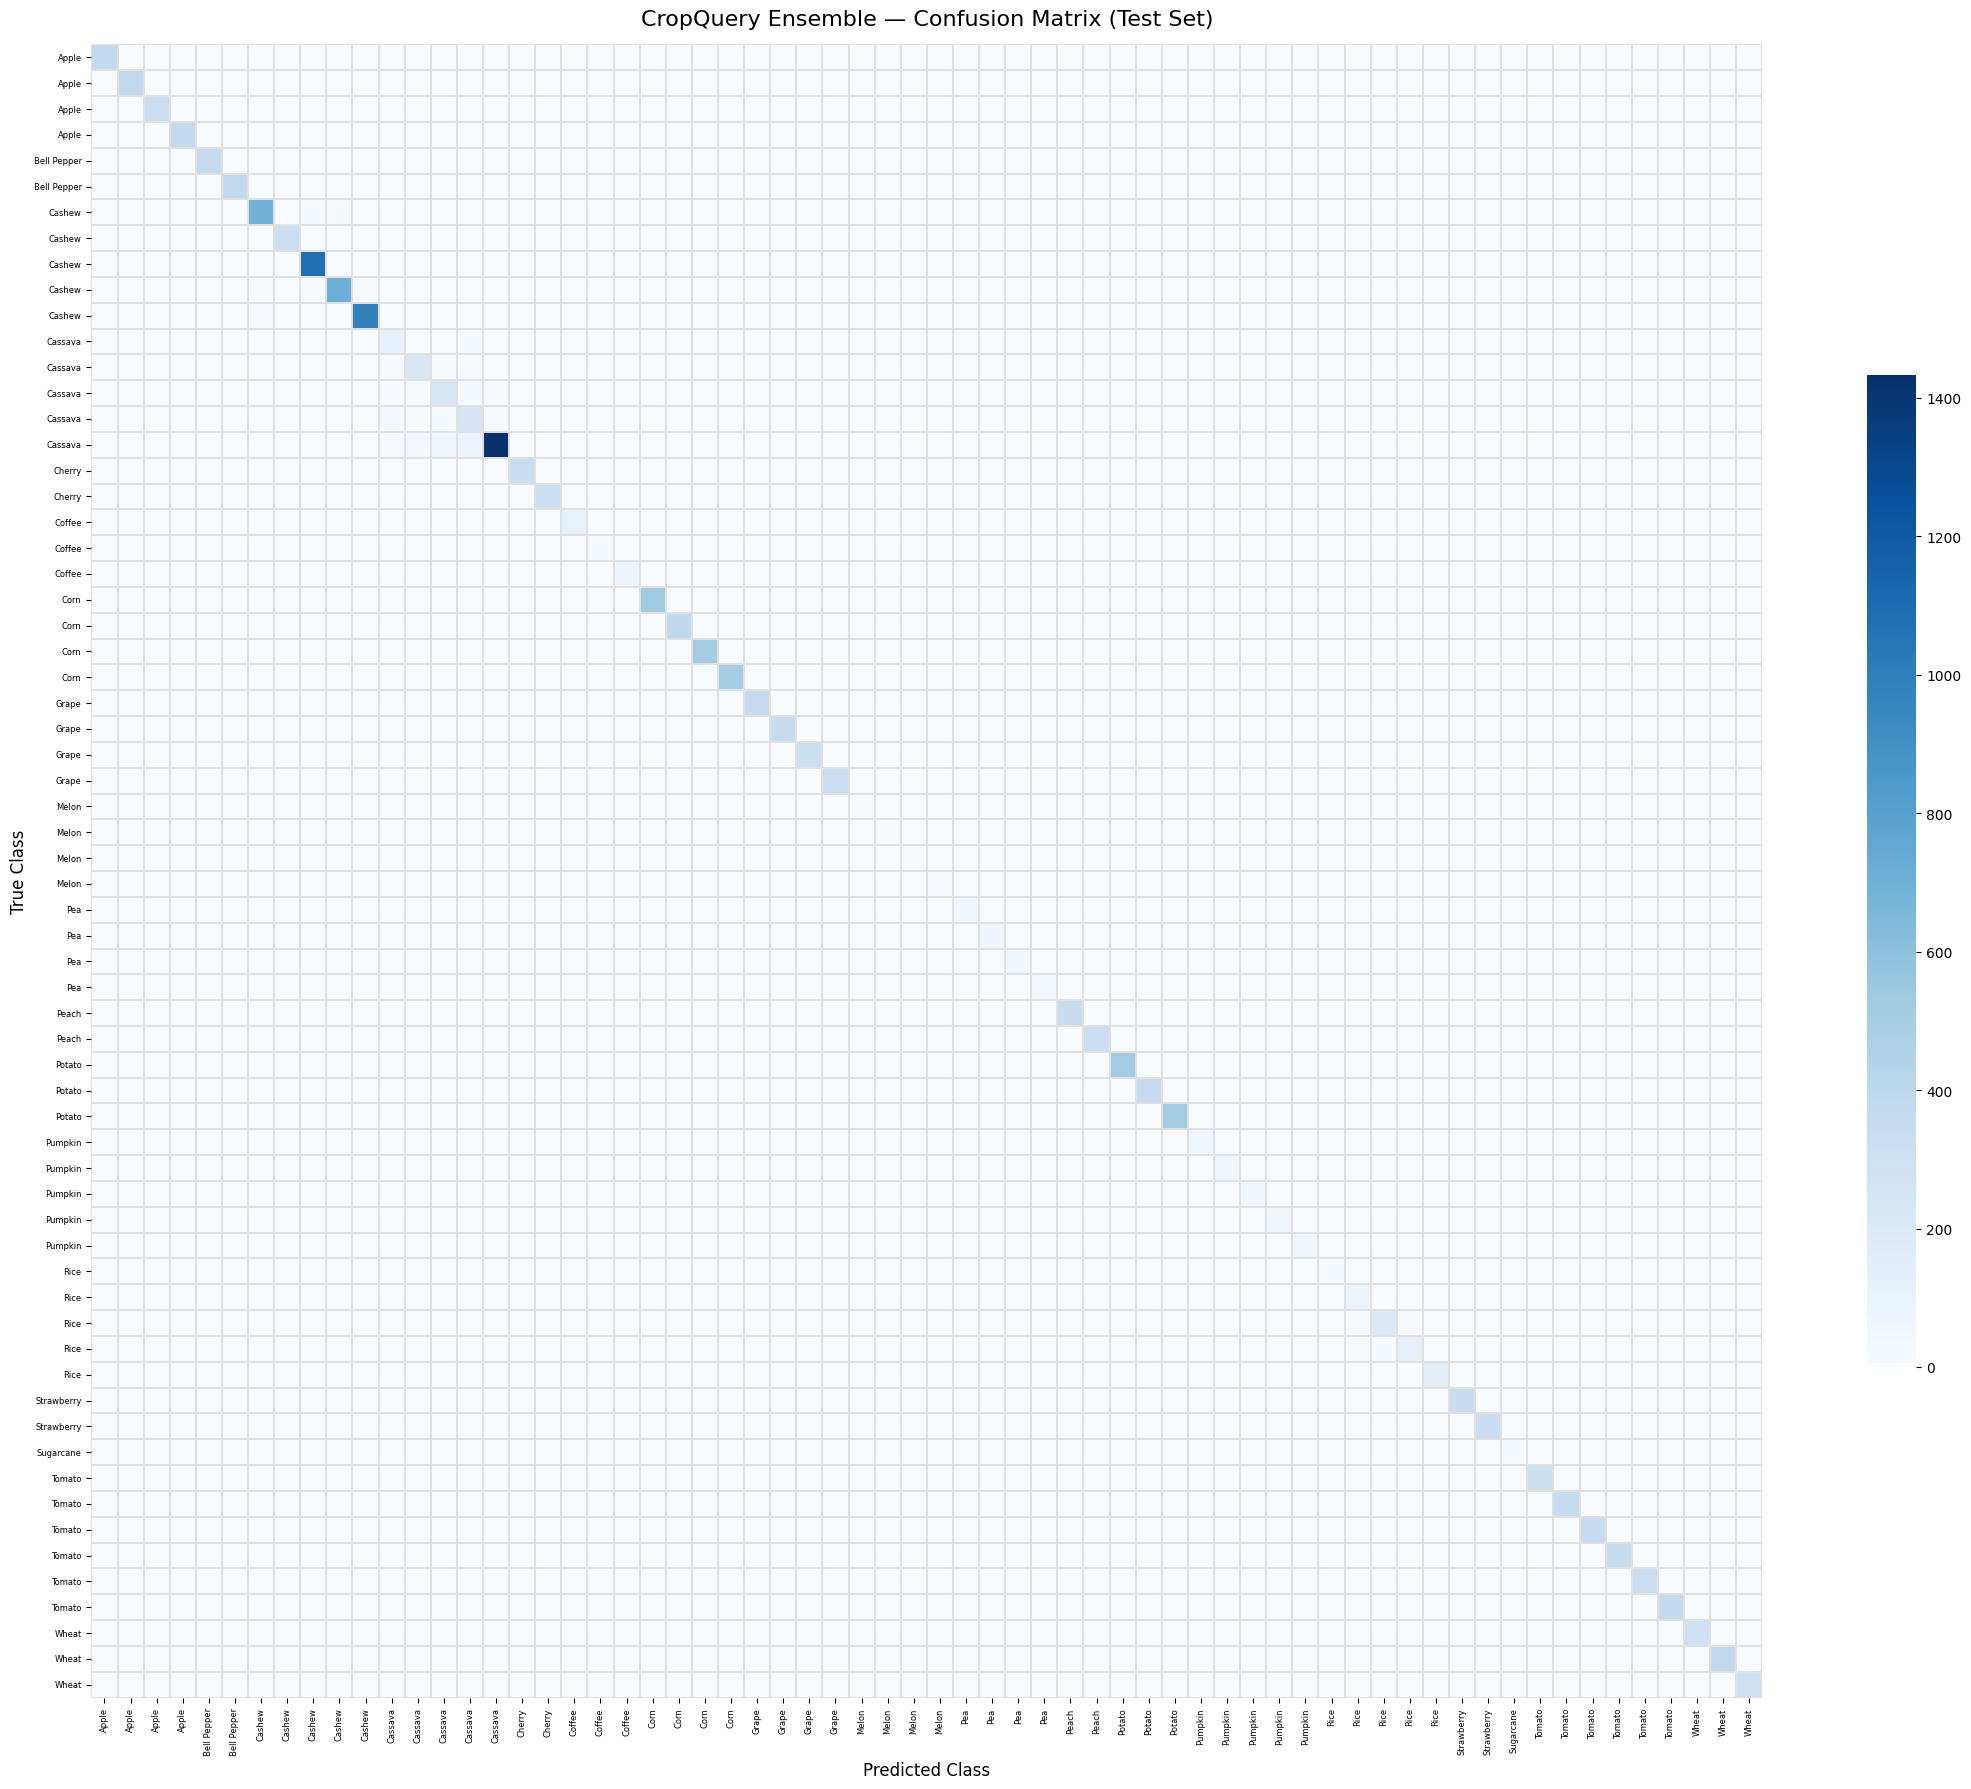

Saved → /kaggle/working/eval_outputs/confusion_matrix.png  (Figure 1 for paper)

Top-10 most confused pairs (True → Predicted : count):
  Cassava__Mosaic_Disease             → Cassava__Healthy                     : 81
  Cassava__Mosaic_Disease             → Cassava__Green_Mottle                : 78
  Cassava__Mosaic_Disease             → Cassava__Brown_Streak_Disease        : 45
  Cassava__Healthy                    → Cassava__Bacterial_Blight            : 35
  Cassava__Green_Mottle               → Cassava__Healthy                     : 30
  Cashew__Anthracnose                 → Cashew__Leaf_Miner                   : 26
  Cassava__Brown_Streak_Disease       → Cassava__Healthy                     : 25
  Cassava__Green_Mottle               → Cassava__Mosaic_Disease              : 20
  Cassava__Brown_Streak_Disease       → Cassava__Bacterial_Blight            : 20
  Cassava__Mosaic_Disease             → Cassava__Bacterial_Blight            : 17
Cassava class indices: [11, 12, 13, 14, 15] 

<Figure size 640x480 with 0 Axes>

In [36]:
# ─── Cell 5: Confusion matrix (64×64) ────────────────────────────────────

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(GT_LABELS_NP, ENSEMBLE_PREDS, labels=list(range(NUM_CLASSES)))

# Short labels for readability (crop name only)
short_labels = [name.split("__")[0].replace("_", " ") for name in CLASS_NAMES]

fig, ax = plt.subplots(figsize=(22, 18))
sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    cmap="Blues",
    xticklabels=short_labels,
    yticklabels=short_labels,
    linewidths=0.3,
    linecolor="#e0e0e0",
    cbar_kws={"shrink": 0.6},
    ax=ax,
)
ax.set_title("CropQuery Ensemble — Confusion Matrix (Test Set)", fontsize=16, pad=14)
ax.set_xlabel("Predicted Class", fontsize=12)
ax.set_ylabel("True Class", fontsize=12)
ax.tick_params(axis="x", rotation=90, labelsize=6)
ax.tick_params(axis="y", rotation=0,  labelsize=6)

plt.tight_layout()
cm_path = f"{OUTPUT_DIR}/confusion_matrix.png"
plt.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved → {cm_path}  (Figure 1 for paper)")

# ── Most confused pairs ───────────────────────────────────────────────────
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)
top_errors = np.dstack(np.unravel_index(np.argsort(cm_no_diag.ravel())[::-1][:10],
                                         cm_no_diag.shape))[0]
print("\nTop-10 most confused pairs (True → Predicted : count):")
for true_i, pred_i in top_errors:
    print(f"  {CLASS_NAMES[true_i]:<35} → {CLASS_NAMES[pred_i]:<35}  : {cm[true_i, pred_i]}")


# Also save as PDF for Overleaf
plt.savefig(f'{OUTPUT_DIR}/confusion_matrix.pdf', dpi=300, bbox_inches='tight')

# Find Cassava class indices for the caption
cassava_indices = [i for i, n in enumerate(CLASS_NAMES) if 'Cassava' in n]
print(f"Cassava class indices: {cassava_indices} — use these in caption")

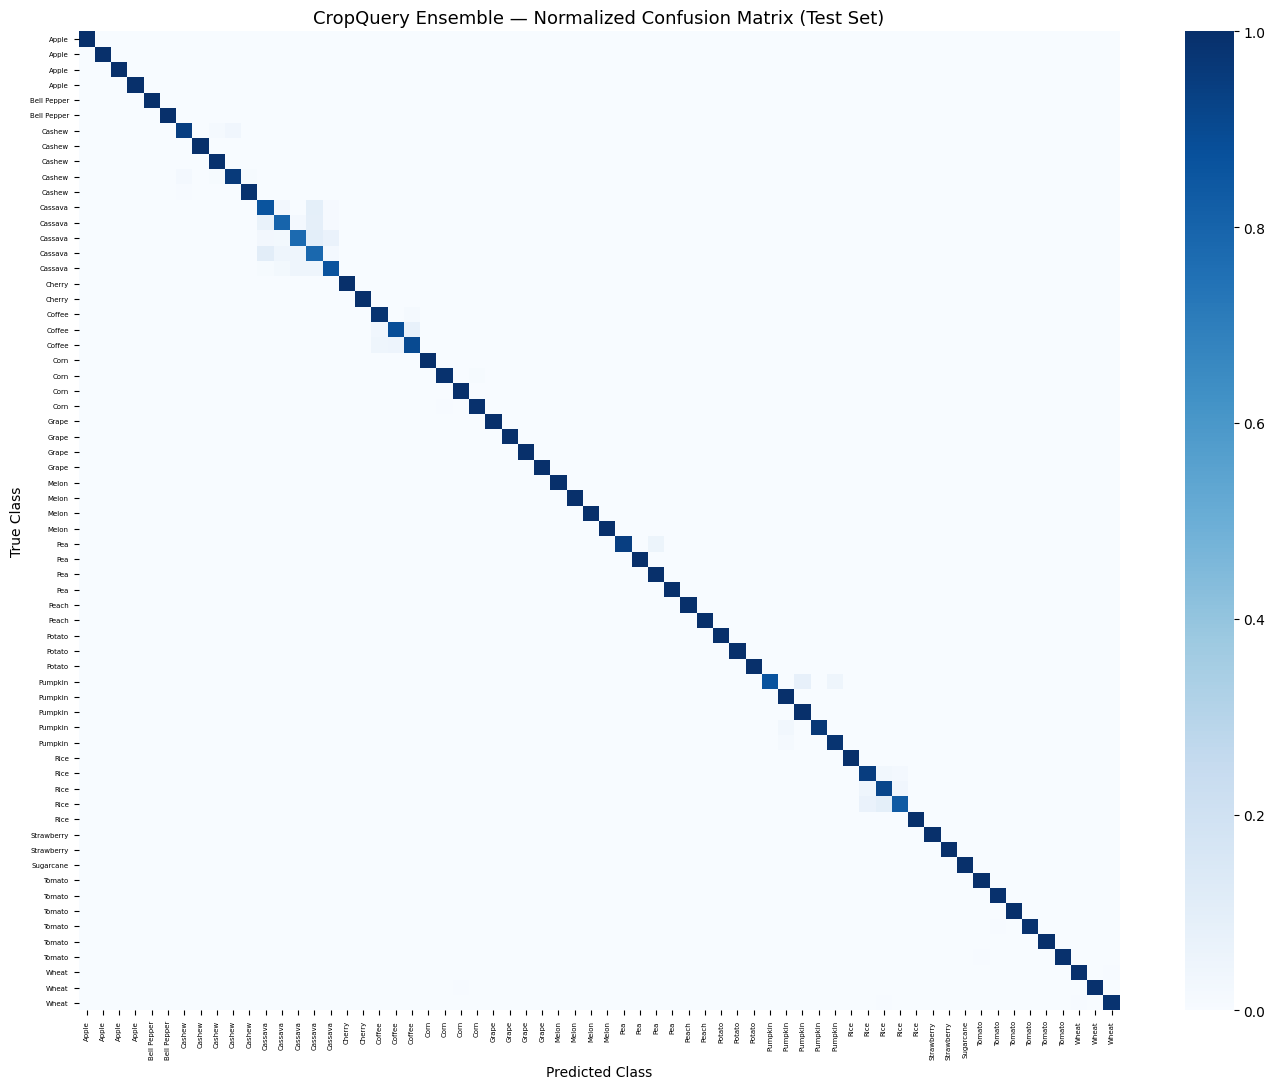

In [38]:
# Normalized confusion matrix — shows % correctly classified per class
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    cm_norm,
    annot=False,
    cmap="Blues",
    vmin=0, vmax=1,
    xticklabels=short_labels,
    yticklabels=short_labels,
    linewidths=0,
    ax=ax,
)
ax.set_title("CropQuery Ensemble — Normalized Confusion Matrix (Test Set)", fontsize=13)
ax.set_xlabel("Predicted Class", fontsize=10)
ax.set_ylabel("True Class", fontsize=10)
ax.tick_params(axis='x', rotation=90, labelsize=5)
ax.tick_params(axis='y', rotation=0, labelsize=5)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/confusion_matrix.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUTPUT_DIR}/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

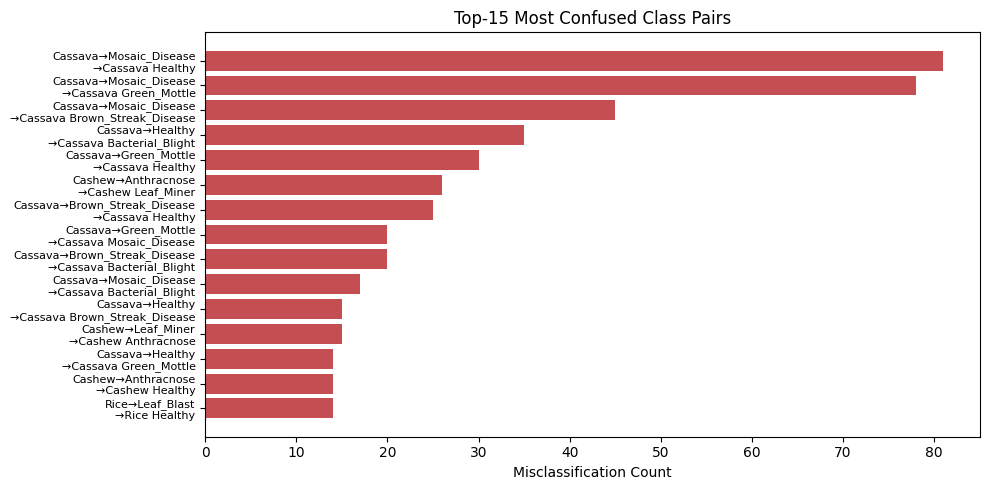

In [39]:
# Top confused pairs — this is the actual research insight
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)
top_errors = np.dstack(np.unravel_index(
    np.argsort(cm_no_diag.ravel())[::-1][:15], cm_no_diag.shape))[0]

labels_err = [f"{CLASS_NAMES[t].replace('__','→')}\n→{CLASS_NAMES[p].replace('__',' ')}"
              for t, p in top_errors]
counts_err = [cm[t, p] for t, p in top_errors]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(labels_err[::-1], counts_err[::-1], color='#C44E52')
ax.set_xlabel('Misclassification Count')
ax.set_title('Top-15 Most Confused Class Pairs')
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/top_errors.pdf', dpi=300, bbox_inches='tight')
plt.show()

---
## Cell 6 — Per-Class F1 Report → CSV

In [32]:
# ─── Cell 6: Per-class F1 report ──────────────────────────────────────────

import pandas as pd
from sklearn.metrics import classification_report

report_dict = classification_report(
    GT_LABELS_NP,
    ENSEMBLE_PREDS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

# Build DataFrame — exclude macro/weighted avg rows
skip_keys = {"accuracy", "macro avg", "weighted avg"}
f1_df = pd.DataFrame(
    [
        {
            "class":     class_name,
            "precision": round(vals["precision"], 4),
            "recall":    round(vals["recall"],    4),
            "f1-score":  round(vals["f1-score"],  4),
            "support":   int(vals["support"]),
        }
        for class_name, vals in report_dict.items()
        if class_name not in skip_keys
    ]
).sort_values("f1-score", ascending=True).reset_index(drop=True)

# Summary metrics
print(f"Macro  F1 : {report_dict['macro avg']['f1-score']:.4f}")
print(f"Weighted F1: {report_dict['weighted avg']['f1-score']:.4f}")
print(f"Accuracy   : {report_dict['accuracy']:.4f}")

# Bottom-10 worst classes — research insight
print("\n── Bottom-10 Worst Classes (by F1) ──────────────────────────────────")
print(f1_df.head(10).to_string(index=False))

# Top-10 best classes
print("\n── Top-10 Best Classes (by F1) ──────────────────────────────────────")
print(f1_df.tail(10).iloc[::-1].to_string(index=False))

# Save full report
f1_path = f"{OUTPUT_DIR}/f1_per_class.csv"
f1_df.to_csv(f1_path, index=False)
print(f"\nSaved → {f1_path}")

Macro  F1 : 0.9660
Weighted F1: 0.9697
Accuracy   : 0.9688

── Bottom-10 Worst Classes (by F1) ──────────────────────────────────
                        class  precision  recall  f1-score  support
             Cassava__Healthy     0.6303  0.7815    0.6978      325
    Cassava__Bacterial_Blight     0.5950  0.8623    0.7041      138
        Cassava__Green_Mottle     0.7030  0.7759    0.7377      299
Cassava__Brown_Streak_Disease     0.7534  0.8000    0.7760      275
      Coffee__Red_Spider_Mite     0.8214  0.8846    0.8519       26
             Rice__Brown_Spot     0.8056  0.9457    0.8700       92
             Rice__Leaf_Blast     0.9173  0.8356    0.8746      146
                Rice__Healthy     0.9148  0.9148    0.9148      223
      Cassava__Mosaic_Disease     0.9775  0.8664    0.9186     1654
                 Coffee__Rust     0.9540  0.9022    0.9274       92

── Top-10 Best Classes (by F1) ──────────────────────────────────────
                      class  precision  recall  f1-

---
## Cell 7 — FAISS Evaluation

In [33]:
# ─── Cell 7: FAISS k-NN evaluation ───────────────────────────────────────
# Compares: Ensemble-only  vs  Ensemble + FAISS (with confidence gate)
import faiss
from tqdm.auto import tqdm

ensemble_probs_all = np.load(f"{OUTPUT_DIR}/ensemble_probs_all.npy")
ensemble_conf = ensemble_probs_all.max(axis=1) * 100  # already numpy, no .numpy() call


# ── Load feature bank ─────────────────────────────────────────────────────
bank_features = np.load(BANK_FEATURES).astype(np.float32)
bank_labels   = np.load(BANK_LABELS)

faiss.normalize_L2(bank_features)
faiss_index = faiss.IndexFlatIP(bank_features.shape[1])
faiss_index.add(bank_features)
print(f"FAISS index: {faiss_index.ntotal} vectors, dim={bank_features.shape[1]}")

# ── Extract test features from all 3 backbones (concatenated) ─────────────
all_features, all_gt_labels = [], []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Extracting features"):
        images = images.to(DEVICE)
        feats  = []
        for model in backbones.values():
            f = model.extract_features(images).cpu().numpy()
            feats.append(f)
        combined = np.concatenate(feats, axis=1)   # (B, 4608)
        all_features.append(combined)
        all_gt_labels.append(labels.numpy())

test_features = np.concatenate(all_features,   axis=0).astype(np.float32)  # (N, 4608)
test_labels   = np.concatenate(all_gt_labels,  axis=0)                     # (N,)

# ── k-NN accuracy ─────────────────────────────────────────────────────────
test_feats_norm = test_features.copy()
faiss.normalize_L2(test_feats_norm)
distances, indices = faiss_index.search(test_feats_norm, KNN_K)

knn_preds = []
for i in range(len(test_labels)):
    neighbour_labels = bank_labels[indices[i]]
    values, counts   = np.unique(neighbour_labels, return_counts=True)
    knn_preds.append(int(values[counts.argmax()]))
knn_preds = np.array(knn_preds)

knn_acc = 100.0 * (knn_preds == test_labels).mean()
print(f"k-NN accuracy (k={KNN_K}): {knn_acc:.2f}%")


hybrid_preds = np.where(
    ensemble_conf >= CONFIDENCE_GATE,
    ENSEMBLE_PREDS,   # high confidence → use ensemble
    knn_preds,        # low confidence  → fall back to FAISS k-NN
)

hybrid_acc  = 100.0 * (hybrid_preds == test_labels).mean()
low_conf_n  = (ensemble_conf < CONFIDENCE_GATE).sum()

print(f"\n{'Method':<30} {'Accuracy':>10}")
print("-" * 42)
print(f"{'Ensemble only':<30} {ens_top1:>9.2f}%")
print(f"{'FAISS k-NN only':<30} {knn_acc:>9.2f}%")
print(f"{'Ensemble + FAISS (hybrid)':<30} {hybrid_acc:>9.2f}%")
print(f"\nImages below confidence gate ({CONFIDENCE_GATE}%): {low_conf_n} "
      f"({100*low_conf_n/len(test_labels):.1f}% of test set)")

# Save
faiss_result = {
    "ensemble_top1":    round(ens_top1, 4),
    "knn_top1":         round(knn_acc, 4),
    "hybrid_top1":      round(hybrid_acc, 4),
    "confidence_gate":  CONFIDENCE_GATE,
    "knn_k":            KNN_K,
    "low_conf_samples": int(low_conf_n),
}
with open(f"{OUTPUT_DIR}/faiss_eval.json", "w") as f:
    json.dump(faiss_result, f, indent=2)
print(f"Saved → {OUTPUT_DIR}/faiss_eval.json")

FAISS index: 113011 vectors, dim=4608


Extracting features:   0%|          | 0/312 [00:00<?, ?it/s]

k-NN accuracy (k=7): 97.84%

Method                           Accuracy
------------------------------------------
Ensemble only                      96.88%
FAISS k-NN only                    97.84%
Ensemble + FAISS (hybrid)          97.84%

Images below confidence gate (80.0%): 7429 (37.2% of test set)
Saved → /kaggle/working/eval_outputs/faiss_eval.json


---
## Cell 8 — AgroBench Evaluation vs GPT-4o Baseline

> ⚠️ **This is the only cell that loads LLaVA.** Run on GPU T4×1; LLaVA runs on `cuda:0`.

In [34]:
# ─── Cell 8: AgroBench evaluation (ROUGE-1, ROUGE-L, BERTScore) ───────────
# Only cell that instantiates LLaVA — kept isolated.

import sys
sys.path.insert(0, "/kaggle/working")

from PIL import Image
from cropquery.retriever      import CropRetriever
from cropquery.advisor        import LLaVAAdvisor
from cropquery.knowledge_base import AGROBENCH_ENTRIES

# ── Install eval libraries if needed ──────────────────────────────────────
!pip install rouge-score bert-score -q

from rouge_score import rouge_scorer as rs_module

scorer = rs_module.RougeScorer(["rouge1", "rougeL"], use_stemmer=True)

# ── Build eval set from AgroBench entries ─────────────────────────────────
EVAL_CASES = []
for entry in AGROBENCH_ENTRIES:
    predicted_class = f"{entry['crop'].replace(' ','_')}__{entry['condition'].replace(' ','_')}"
    EVAL_CASES.append({
        "predicted_class": predicted_class,
        "crop":            entry["crop"],
        "condition":       entry["condition"],
        "question":        f"My {entry['crop'].lower()} has {entry['condition'].lower()}. "
                           f"What should I do?",
        "reference":       entry["text"],
    })
print(f"AgroBench eval cases: {len(EVAL_CASES)}")

# ── Load pipeline components ──────────────────────────────────────────────
retriever   = CropRetriever()
advisor     = LLaVAAdvisor()   # loads LLaVA 4-bit on cuda:0
blank_image = Image.new("RGB", (224, 224), color=(200, 200, 200))

# ── Run evaluation ────────────────────────────────────────────────────────
rouge1_scores, rougeL_scores = [], []
per_case_results = []

for i, case in enumerate(EVAL_CASES):
    chunks  = retriever.retrieve(case["predicted_class"], case["question"])
    context = retriever.build_rag_context(chunks)

    try:
        advice = advisor.generate(
            image           = blank_image,
            rag_context     = context,
            farmer_question = case["question"],
            resnet_hint     = case["predicted_class"],
            confidence      = 90.0,
            weather_ctx     = None,
            location_ctx    = None,
        )
    except Exception as e:
        advice = ""
        print(f"  ✗ [{i+1}] {case['crop']}/{case['condition']}: {e}")

    scores = scorer.score(case["reference"], advice)
    r1     = scores["rouge1"].fmeasure
    rL     = scores["rougeL"].fmeasure
    rouge1_scores.append(r1)
    rougeL_scores.append(rL)

    per_case_results.append({
        "case":    f"{case['crop']} / {case['condition']}",
        "rouge1":  round(r1, 4),
        "rougeL":  round(rL, 4),
        "advice":  advice[:250],
    })
    print(f"  [{i+1:02d}/{len(EVAL_CASES)}] {case['crop']:<15} {case['condition']:<25} "
          f"R-1: {r1:.3f}  R-L: {rL:.3f}")

# ── BERTScore (optional — comment out if slow) ────────────────────────────
try:
    from bert_score import score as bert_score_fn
    hypotheses = [r["advice"] for r in per_case_results]
    references = [c["reference"] for c in EVAL_CASES]
    P, R, F1   = bert_score_fn(hypotheses, references, lang="en", verbose=False)
    bert_f1_mean = F1.mean().item()
    print(f"\nBERTScore F1 (mean): {bert_f1_mean:.4f}")
except ImportError:
    bert_f1_mean = None
    print("\nbert-score not installed — skipping BERTScore")

# ── Summary vs GPT-4o baseline ────────────────────────────────────────────
GPT4O_BASELINE = 0.7345
mean_r1 = np.mean(rouge1_scores)
mean_rL = np.mean(rougeL_scores)

print(f"\n{'─'*58}")
print(f"CropQuery ROUGE-1 (mean) : {mean_r1:.4f}  ({mean_r1*100:.2f}%)")
print(f"CropQuery ROUGE-L (mean) : {mean_rL:.4f}  ({mean_rL*100:.2f}%)")
if bert_f1_mean:
    print(f"CropQuery BERTScore F1   : {bert_f1_mean:.4f}  ({bert_f1_mean*100:.2f}%)")
print(f"GPT-4o baseline          : {GPT4O_BASELINE:.4f}  ({GPT4O_BASELINE*100:.2f}%)")
print(f"Delta vs GPT-4o (ROUGE-1): {mean_r1 - GPT4O_BASELINE:+.4f}")
print(f"{'─'*58}")

# ── Save ──────────────────────────────────────────────────────────────────
agrobench_result = {
    "cropquery_rouge1_mean":  round(float(mean_r1), 4),
    "cropquery_rougeL_mean":  round(float(mean_rL), 4),
    "cropquery_bertf1_mean":  round(float(bert_f1_mean), 4) if bert_f1_mean else None,
    "gpt4o_baseline":         GPT4O_BASELINE,
    "delta_vs_gpt4o":         round(float(mean_r1 - GPT4O_BASELINE), 4),
    "n_cases":                len(EVAL_CASES),
    "per_case":               per_case_results,
}
with open(f"{OUTPUT_DIR}/agrobench_eval.json", "w") as f:
    json.dump(agrobench_result, f, indent=2)
print(f"Saved → {OUTPUT_DIR}/agrobench_eval.json")

ModuleNotFoundError: No module named 'cropquery'

---
## Cell 9 — RAG Retrieval Quality (Recall@k)

In [ ]:
# ─── Cell 9: RAG retrieval quality — Recall@1/3/5 ─────────────────────────
# For each AgroBench case, checks whether the correct disease chunk
# appears in the top-k retrieved chunks.
# Target: 94.70% Recall@5 for the paper.

import sys
sys.path.insert(0, "/kaggle/working")
from cropquery.retriever      import CropRetriever
from cropquery.knowledge_base import AGROBENCH_ENTRIES

retriever = CropRetriever()

K_VALUES = [1, 3, 5]
recall_at_k = {k: [] for k in K_VALUES}
detail_rows = []

for entry in AGROBENCH_ENTRIES:
    predicted_class  = f"{entry['crop'].replace(' ','_')}__{entry['condition'].replace(' ','_')}"
    question         = f"My {entry['crop'].lower()} has {entry['condition'].lower()}. What should I do?"
    reference_tokens = set(re.findall(r'\b\w+\b', entry["text"].lower()))

    # Retrieve top-5 (superset covers all K values)
    chunks = retriever.retrieve(predicted_class, question, top_k=max(K_VALUES))

    row = {"case": f"{entry['crop']} / {entry['condition']}"}
    for k in K_VALUES:
        top_k_text   = " ".join(c.page_content if hasattr(c, "page_content")
                                else str(c) for c in chunks[:k])
        chunk_tokens = set(re.findall(r'\b\w+\b', top_k_text.lower()))

        # Overlap with reference as proxy for "correct chunk retrieved"
        hit = len(reference_tokens & chunk_tokens) / max(len(reference_tokens), 1) > 0.25
        recall_at_k[k].append(int(hit))
        row[f"hit@{k}"] = hit

    detail_rows.append(row)

# ── Print results ─────────────────────────────────────────────────────────
print(f"RAG Retrieval Quality — {len(AGROBENCH_ENTRIES)} AgroBench cases")
print(f"{'─'*40}")
for k in K_VALUES:
    recall = 100.0 * np.mean(recall_at_k[k])
    print(f"  Recall@{k}: {recall:.2f}%")

# Failures
failures = [r for r in detail_rows if not r["hit@5"]]
if failures:
    print(f"\n  Cases not retrieved in top-5:")
    for r in failures:
        print(f"    ✗ {r['case']}")
else:
    print("\n  ✅ All cases retrieved in top-5")

# Save
rag_result = {
    **{f"recall_at_{k}": round(100.0 * np.mean(recall_at_k[k]), 2) for k in K_VALUES},
    "n_cases":  len(AGROBENCH_ENTRIES),
    "per_case": detail_rows,
}
with open(f"{OUTPUT_DIR}/rag_recall.json", "w") as f:
    json.dump(rag_result, f, indent=2)
print(f"\nSaved → {OUTPUT_DIR}/rag_recall.json")

---
## Cell 10 — Results Summary Table (Paper-Ready)

In [ ]:
# ─── Cell 10: Results summary — copy-paste ready for the paper ────────────

import json, pandas as pd
from pathlib import Path

# ── Load saved results ────────────────────────────────────────────────────
def load_json(name):
    path = Path(OUTPUT_DIR) / name
    if path.exists():
        with open(path) as f:
            return json.load(f)
    print(f"  ⚠️  {name} not found — run the corresponding cell first")
    return {}

ablation  = pd.read_csv(f"{OUTPUT_DIR}/ablation_accuracy.csv", index_col=0) \
              if Path(f"{OUTPUT_DIR}/ablation_accuracy.csv").exists() else None
faiss_r   = load_json("faiss_eval.json")
agro_r    = load_json("agrobench_eval.json")
rag_r     = load_json("rag_recall.json")

# ── Table 1: Vision Backbone Accuracy ────────────────────────────────────
print("=" * 60)
print("TABLE 1 — Vision Backbone Accuracy (Test Set)")
print("=" * 60)
if ablation is not None:
    print(ablation.to_string())
else:
    print("  (run Cell 4)")

# ── Table 2: FAISS Comparison ─────────────────────────────────────────────
print("\n" + "=" * 60)
print("TABLE 2 — FAISS k-NN Comparison")
print("=" * 60)
if faiss_r:
    rows = [
        ("Ensemble only",           faiss_r.get("ensemble_top1", "—")),
        (f"FAISS k-NN (k={faiss_r.get('knn_k','?')})", faiss_r.get("knn_top1", "—")),
        ("Ensemble + FAISS (hybrid)", faiss_r.get("hybrid_top1", "—")),
    ]
    faiss_df = pd.DataFrame(rows, columns=["Method", "Top-1 Acc (%)"])
    print(faiss_df.to_string(index=False))
    print(f"\n  Confidence gate: {faiss_r.get('confidence_gate')}%  "
          f"| Low-conf samples: {faiss_r.get('low_conf_samples')}")
else:
    print("  (run Cell 7)")

# ── Table 3: AgroBench ────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("TABLE 3 — AgroBench Evaluation vs GPT-4o Baseline")
print("=" * 60)
if agro_r:
    agro_rows = [
        ("CropQuery (LLaVA+RAG)",
         f"{agro_r.get('cropquery_rouge1_mean','—')}",
         f"{agro_r.get('cropquery_rougeL_mean','—')}",
         f"{agro_r.get('cropquery_bertf1_mean','—')}"),
        ("GPT-4o baseline",
         f"{agro_r.get('gpt4o_baseline','—')}",
         "—", "—"),
    ]
    agro_df = pd.DataFrame(
        agro_rows,
        columns=["System", "ROUGE-1", "ROUGE-L", "BERTScore F1"],
    )
    print(agro_df.to_string(index=False))
    delta = agro_r.get("delta_vs_gpt4o", 0)
    symbol = "▲" if delta > 0 else "▼"
    print(f"\n  Δ vs GPT-4o: {delta:+.4f} {symbol}  "
          f"({agro_r.get('n_cases')} AgroBench cases)")
else:
    print("  (run Cell 8)")

# ── Table 4: RAG Recall ───────────────────────────────────────────────────
print("\n" + "=" * 60)
print("TABLE 4 — RAG Retrieval Quality")
print("=" * 60)
if rag_r:
    rag_rows = [
        ("Recall@1", f"{rag_r.get('recall_at_1','—')}%"),
        ("Recall@3", f"{rag_r.get('recall_at_3','—')}%"),
        ("Recall@5", f"{rag_r.get('recall_at_5','—')}%"),
    ]
    rag_df = pd.DataFrame(rag_rows, columns=["Metric", "Value"])
    print(rag_df.to_string(index=False))
    print(f"  ({rag_r.get('n_cases')} AgroBench cases)")
else:
    print("  (run Cell 9)")

print("\n" + "=" * 60)
print("All outputs saved to:", OUTPUT_DIR)
print("=" * 60)

import os
for fname in sorted(os.listdir(OUTPUT_DIR)):
    size = os.path.getsize(f"{OUTPUT_DIR}/{fname}")
    print(f"  {fname:<35} {size:>8,} bytes")